# Is the awake 7–8 Hz line running?

Mouse 720762. The awake spectra show a narrow line around 7–8 Hz. Locomotion drives theta (about 6–9 Hz), strongest in
hippocampus, so the question is whether this line follows running.

**Signals:** deep prelimbic LFP (PL5, our motif channel), hippocampal CA3 LFP, frontal EEG channel 13 (MOs) and EEG
channel 2 (retrosplenial).

**Method**
- Spectrogram at 250 Hz: 2-s Hann windows, 1-s steps.
- Per second:
  - 7–8 Hz power (dB);
  - the 7–8 Hz peak height above its neighbours (dB above the mean of 4–6 and 10–12 Hz), which separates a real
    spectral line from overall power changes;
  - peak frequency within 5–10 Hz.
- Running: wheel speed averaged per second. The raw signal is a 100-Hz encoder reading of either 0 or about 30 cm/s.
- Running = above 5 cm/s; still = below 0.5 cm/s.
- Under isoflurane the mouse does not run, which is a built-in control: if the line is present there too, running
  can't explain it.
- Correlations use a null of the speed series circularly shifted by at least 60 s.

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.signal import spectrogram
from scipy.stats import spearmanr
sys.path.insert(0, "..")
from src import session_data as sd, motif_tracking as mt
from src.channel_sweep import list_signals
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
REPO = Path.cwd().resolve().parents[2]
NWB = REPO / "data" / "raw" / "720762-20240221-v001.nwb"
OUT = REPO / "data" / "out" / "2026-11-10_theta_running"; OUT.mkdir(parents=True, exist_ok=True)
def save(fig, name): fig.savefig(OUT / f"{name}.png", dpi=150, bbox_inches="tight", facecolor="white")
FS = 250.0
info, (run_t, run), (pupil_t, pupil) = mt.behaviour(NWB)
io, nwb = sd.open_nwb(NWB)
sigs = {s["key"]: s for s in list_signals(nwb)}
SOURCES = {"PL5 LFP": ("lfp", "probeF", sd.lfp_channel(nwb, "probeF", "PL5")),
           "CA3 LFP": ("lfp", sigs["lfp_CA3"]["source"][1], sd.lfp_channel(nwb, sigs["lfp_CA3"]["source"][1], "CA3")),
           "EEG ch13 (MOs)": ("eeg", 13), "EEG ch2 (RSP)": ("eeg", 2)}
SPEC = {}
for name, src in SOURCES.items():
    t, x, fs = sd.decimate(*sd.read_raw(nwb, src), FS)
    f, tt, P = spectrogram(x, fs=fs, window="hann", nperseg=int(2 * fs), noverlap=int(fs), scaling="density")
    keep = f <= 45
    SPEC[name] = (t[0] + tt, f[keep], 10 * np.log10(P[keep] + 1e-20))
io.close()
tsec = SPEC["PL5 LFP"][0]
edges = np.searchsorted(run_t, np.r_[tsec - 1, tsec[-1] + 1])  # 2-s window centred on each spectrogram time
csum = np.r_[0, np.cumsum(run)]
lo, hi = np.searchsorted(run_t, tsec - 1), np.searchsorted(run_t, tsec + 1)
speed = (csum[hi] - csum[lo]) / np.maximum(hi - lo, 1)
okp = np.isfinite(pupil)
pup = np.interp(tsec, pupil_t[okp], pupil[okp])
state = sd.state_of_time(tsec, info)
stim = np.zeros(tsec.size, bool)
for _, a, b in list(info.stim_blocks) + list(info.visual_blocks):
    stim |= (tsec >= a - 5) & (tsec < b + 5)
awake, iso = state == "awake", state == "isoflurane"
running, still = awake & (speed > 5), awake & (speed < 0.5)
pd.Series({"awake seconds": int(awake.sum()), "running (>5 cm/s)": int(running.sum()), "still (<0.5 cm/s)": int(still.sum()),
           "isoflurane seconds": int(iso.sum()), "isoflurane seconds with speed > 0.5": int((iso & (speed > 0.5)).sum())})

awake seconds                          3247
running (>5 cm/s)                      3244
still (<0.5 cm/s)                         0
isoflurane seconds                     3804
isoflurane seconds with speed > 0.5       4
dtype: int64

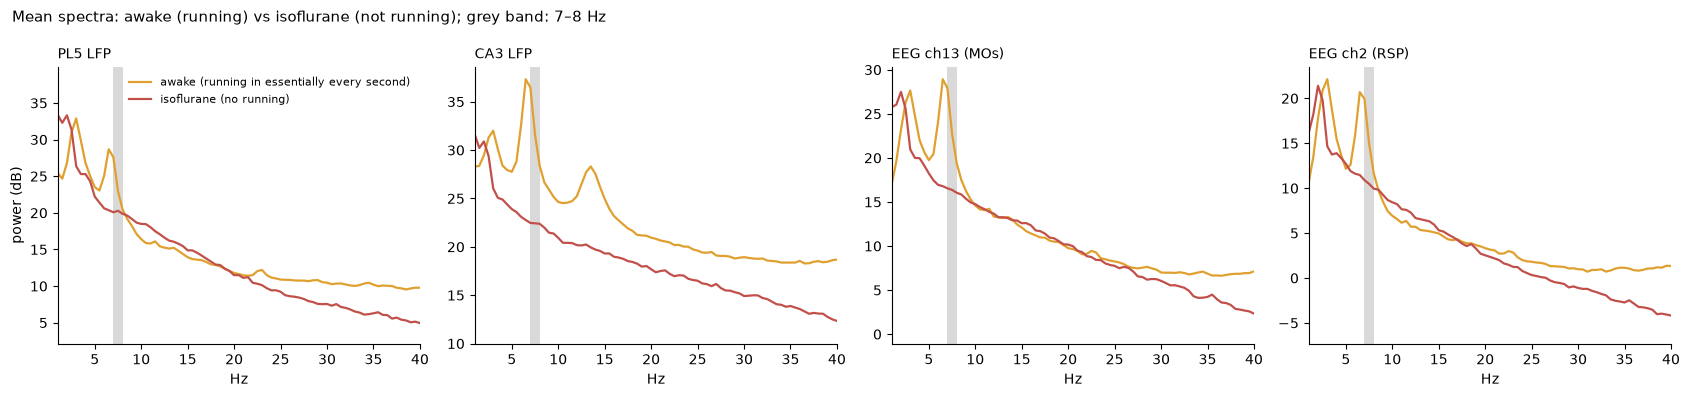

In [2]:
def band_feats(f, P):
    b78 = (f >= 7) & (f <= 8)
    nb = ((f >= 4) & (f <= 6)) | ((f >= 10) & (f <= 12))
    win = (f >= 5) & (f <= 10)
    p78 = P[b78].mean(0)
    return {"p78": p78, "peak_dB": p78 - P[nb].mean(0), "peak_hz": f[win][np.argmax(P[win], axis=0)]}
FEAT = {k: band_feats(f, P) for k, (_, f, P) in SPEC.items()}

fig, axes = plt.subplots(1, 4, figsize=(17, 4), sharex=True)
for ax, (name, (tt, f, P)) in zip(axes, SPEC.items()):
    for m, lab, col in ((running, "awake (running in essentially every second)", "#E0A030"),
                        (iso & ~stim, "isoflurane (no running)", "#C2504A")):
        ax.plot(f, P[:, m].mean(1), color=col, lw=1.6, label=lab)
    ax.axvspan(7, 8, color="0.85", lw=0, zorder=0)
    ax.set_title(name, fontsize=10, loc="left"); ax.set_xlabel("Hz"); ax.set_xlim(1, 40)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("power (dB)"); axes[0].legend(fontsize=8, frameon=False)
fig.suptitle("Mean spectra: awake (running) vs isoflurane (not running); grey band: 7–8 Hz", fontsize=11, x=0.01, ha="left")
fig.tight_layout(); save(fig, "1_spectra_by_running"); plt.show()

## Does 7–8 Hz power follow running speed?

In [3]:
rng = np.random.default_rng(0)
def shift_r(x, y, n=500, min_shift=60):
    r = spearmanr(x, y).correlation
    ks = rng.integers(min_shift, x.size - min_shift, n)
    null = np.array([spearmanr(np.roll(x, k), y).correlation for k in ks])
    return r, float((1 + (np.abs(null) >= abs(r)).sum()) / (n + 1)), float(np.percentile(np.abs(null), 95))
rows = []
for name, F in FEAT.items():
    for lab, m in (("all awake", awake), ("spontaneous awake", awake & ~stim)):
        row = {"signal": name, "seconds": lab}
        for feat in ("p78", "peak_dB"):
            r, p, n95 = shift_r(speed[m], F[feat][m])
            row[f"r(speed, {feat})"] = r; row[f"p {feat}"] = p; row[f"null95 {feat}"] = n95
        r, p, n95 = shift_r(pup[m], F["peak_dB"][m]); row["r(pupil, peak_dB)"] = r; row["p pupil"] = p
        row["peak height running (dB)"] = F["peak_dB"][m & running].mean()
        row["peak height still (dB)"] = F["peak_dB"][m & still].mean()
        row["peak height isoflurane (dB)"] = F["peak_dB"][iso & ~stim].mean()
        row["peak Hz running"] = np.median(F["peak_hz"][m & running]); row["peak Hz still"] = np.median(F["peak_hz"][m & still])
        rows.append(row)
stats = pd.DataFrame(rows); stats.to_csv(OUT / "stats.csv", index=False)
stats.round(3)

,signal,seconds,"r(speed, p78)",p p78,null95 p78,"r(speed, peak_dB)",p peak_dB,null95 peak_dB,"r(pupil, peak_dB)",p pupil,peak height running (dB),peak height still (dB),peak height isoflurane (dB),peak Hz running,peak Hz still
0,PL5 LFP,all awake,0.071,0.006,0.052,0.063,0.008,0.050,-0.020,0.764,4.945,NaN,-0.534,6.5,NaN
1,PL5 LFP,spontaneous awake,0.040,0.194,0.058,0.015,0.649,0.066,-0.081,0.024,5.806,NaN,-0.534,6.5,NaN
2,CA3 LFP,all awake,0.184,0.002,0.078,0.178,0.002,0.051,0.008,0.888,7.605,NaN,0.087,6.5,NaN
3,CA3 LFP,spontaneous awake,0.125,0.002,0.069,0.144,0.002,0.070,0.126,0.022,7.720,NaN,0.087,6.5,NaN
4,EEG ch13 (MOs),all awake,0.122,0.002,0.061,0.125,0.002,0.041,0.043,0.106,7.845,NaN,-0.045,6.5,NaN
5,EEG ch13 (MOs),spontaneous awake,0.087,0.020,0.067,0.088,0.012,0.063,0.052,0.070,8.332,NaN,-0.045,6.5,NaN
6,EEG ch2 (RSP),all awake,0.175,0.002,0.072,0.121,0.002,0.042,0.042,0.096,7.466,NaN,0.219,6.5,NaN
7,EEG ch2 (RSP),spontaneous awake,0.132,0.002,0.068,0.087,0.010,0.064,0.005,0.848,7.961,NaN,0.219,6.5,NaN


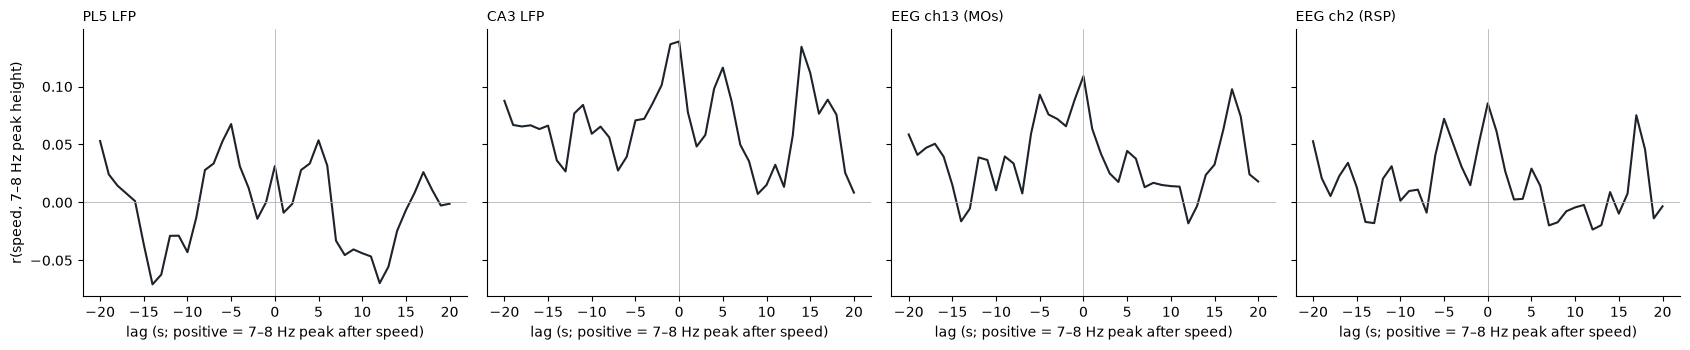

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6), sharey=True)
lags = np.arange(-20, 21)
for ax, (name, F) in zip(axes, FEAT.items()):
    m = awake & ~stim
    s, y = speed[m] - speed[m].mean(), F["peak_dB"][m] - F["peak_dB"][m].mean()
    xc = [np.corrcoef(s[max(0, -L):s.size - max(0, L)], y[max(0, L):y.size - max(0, -L)])[0, 1] for L in lags]
    ax.plot(lags, xc, color="#1D232B"); ax.axvline(0, color="0.7", lw=0.6); ax.axhline(0, color="0.7", lw=0.6)
    ax.set_title(name, fontsize=10, loc="left"); ax.set_xlabel("lag (s; positive = 7–8 Hz peak after speed)")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("r(speed, 7–8 Hz peak height)")
fig.tight_layout(); save(fig, "2_lagged_correlation"); plt.show()

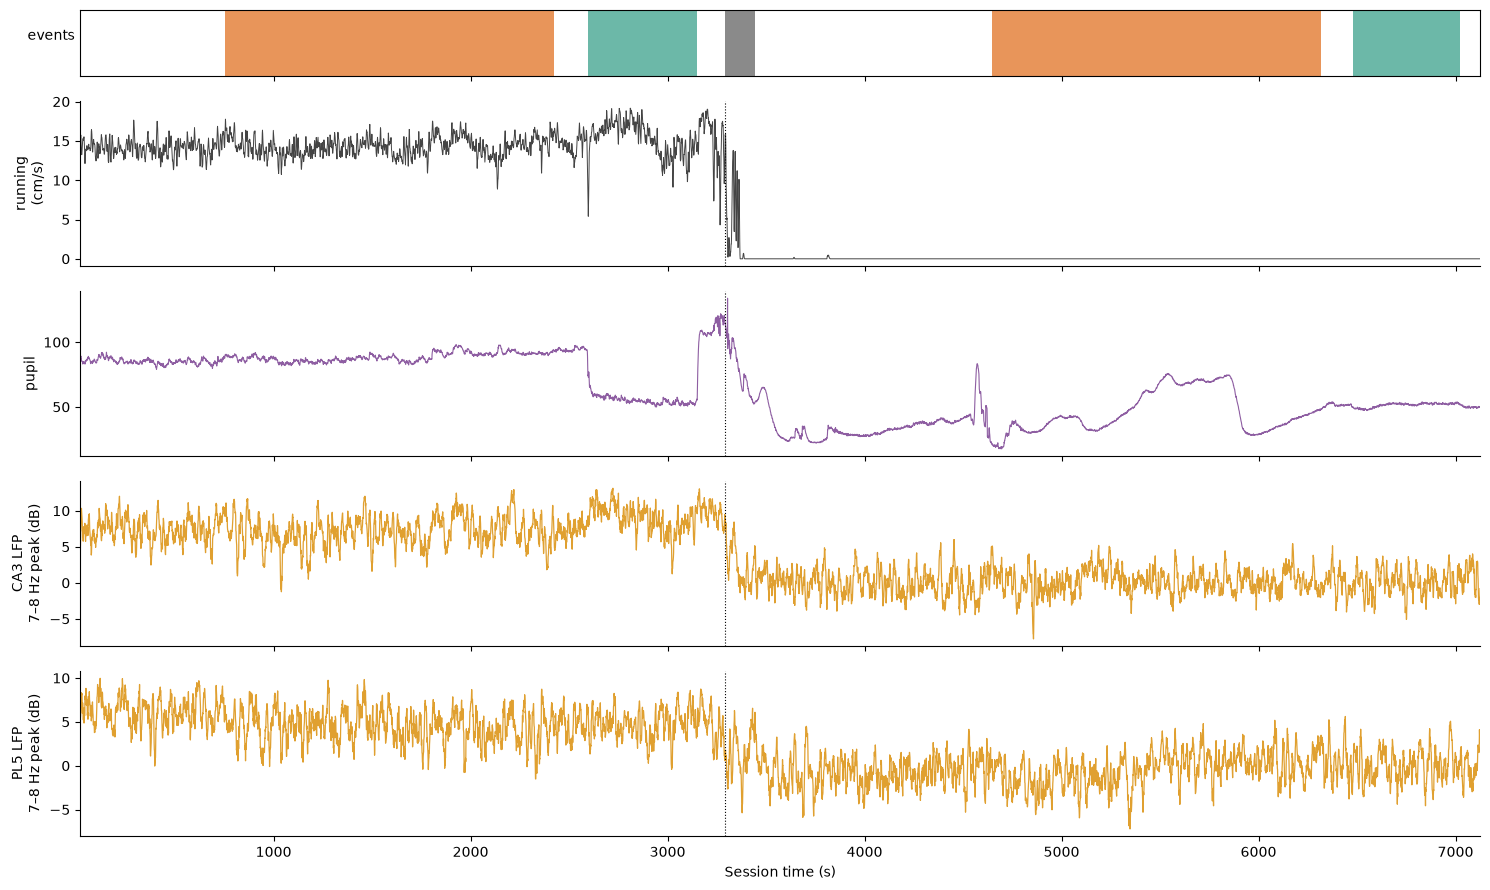

In [5]:
def smooth(v, n):
    return np.convolve(v, np.ones(n) / n, mode="same")
fig, axes = plt.subplots(5, 1, figsize=(15, 9), sharex=True, gridspec_kw={"height_ratios": [0.4, 1, 1, 1, 1]})
for _, a, b in info.stim_blocks: axes[0].axvspan(a, b, color="#E8955A", lw=0)
for _, a, b in info.visual_blocks: axes[0].axvspan(a, b, color="#6CB8A8", lw=0)
axes[0].axvspan(info.iso_on, info.induction_end, color="#8A8A8A", lw=0); axes[0].set_yticks([]); axes[0].set_ylabel("events", rotation=0, ha="right")
axes[1].plot(tsec, smooth(speed, 5), color="#444444", lw=0.7); axes[1].set_ylabel("running\n(cm/s)")
axes[2].plot(tsec, pup, color="#8E5EA2", lw=0.8); axes[2].set_ylabel("pupil")
for ax, name in zip(axes[3:], ("CA3 LFP", "PL5 LFP")):
    ax.plot(tsec, smooth(FEAT[name]["peak_dB"], 10), color="#E0A030", lw=0.9); ax.set_ylabel(f"{name}\n7–8 Hz peak (dB)")
axes[-1].set_xlabel("Session time (s)"); axes[0].set_xlim(tsec[0], info.iso_off)
for ax in axes[1:]:
    ax.axvline(info.iso_on, color="k", ls=":", lw=0.8); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); save(fig, "3_timeline"); plt.show()

## Separating running from anaesthesia

While awake the mouse runs in essentially every second (per-second speed above 5 cm/s in 3,244 of 3,247 awake seconds),
so there is no awake "still" condition, and the awake vs isoflurane contrast confounds running with the drug. Two
partial checks:
- **Around induction** (from 2 min before isoflurane on to the end of induction), running becomes intermittent while
  the drug takes hold: compare stopped seconds (speed < 0.5) with running seconds (> 5) in the same stretch.
- **Within awake**, compare the slowest fifth of seconds with the fastest fifth.

In [6]:
ind = (tsec >= info.iso_on - 120) & (tsec < info.induction_end)
rows = []
for name, F in FEAT.items():
    pk = F["peak_dB"]
    a = awake & ~stim
    q20, q80 = np.percentile(speed[a], [20, 80])
    def diff_p(m1, m0, n=2000):
        d = pk[m1].mean() - pk[m0].mean()
        both = np.r_[pk[m1], pk[m0]]; k = m1.sum()
        null = np.array([(lambda s: s[:k].mean() - s[k:].mean())(rng.permutation(both)) for _ in range(n)])
        return d, float((1 + (np.abs(null) >= abs(d)).sum()) / (n + 1))
    d_ind, p_ind = diff_p(ind & (speed > 5), ind & (speed < 0.5))
    d_aw, p_aw = diff_p(a & (speed >= q80), a & (speed <= q20))
    rows.append({"signal": name,
                 "induction: running s": int((ind & (speed > 5)).sum()), "induction: stopped s": int((ind & (speed < 0.5)).sum()),
                 "induction: peak running − stopped (dB)": d_ind, "p (shuffle)": p_ind,
                 "awake: fastest − slowest fifth (dB)": d_aw, "p awake (shuffle)": p_aw,
                 "awake peak (dB)": pk[a].mean(), "isoflurane peak (dB)": pk[iso & ~stim].mean()})
ctrl = pd.DataFrame(rows); ctrl.to_csv(OUT / "controls.csv", index=False)
print("awake speed fifths (cm/s):", np.percentile(speed[awake & ~stim], [20, 80]).round(1))
ctrl.round(3)

awake speed fifths (cm/s): [12.9 15.8]


,signal,induction: running s,induction: stopped s,induction: peak running − stopped (dB),p (shuffle),awake: fastest − slowest fifth (dB),p awake (shuffle),awake peak (dB),isoflurane peak (dB)
0,PL5 LFP,151,89,2.699,0.0,0.177,0.713,5.806,-0.534
1,CA3 LFP,151,89,7.726,0.0,2.037,0.000,7.720,0.087
2,EEG ch13 (MOs),151,89,6.536,0.0,1.446,0.003,8.332,-0.045
3,EEG ch2 (RSP),151,89,6.318,0.0,1.148,0.023,7.961,0.219


## Is the 7 Hz rhythm the stepping rhythm?

If each step jolts the wheel, wheel speed oscillates at the stride frequency. The wheel signal is sampled at 100 Hz (an
encoder reading of 0 or about 30 cm/s per sample), so its spectrum below about 20 Hz shows how speed fluctuates.

Three checks on awake time:
1. **The wheel's own spectrum:** where is its rhythm?
2. **Does that rhythm, and the brain's 7 Hz peak, shift with speed** (10-s segments split into slow, middle and fast
   thirds)? A gait rhythm should speed up as the mouse runs faster.
3. **Coherence between the wheel signal and each brain signal:** if the brain's 7 Hz rhythm were driven by steps, or
   were a movement artefact, the two would be coherent at 7 Hz. Null: the wheel signal shifted by at least 60 s
   (20 shifts, 95th percentile).

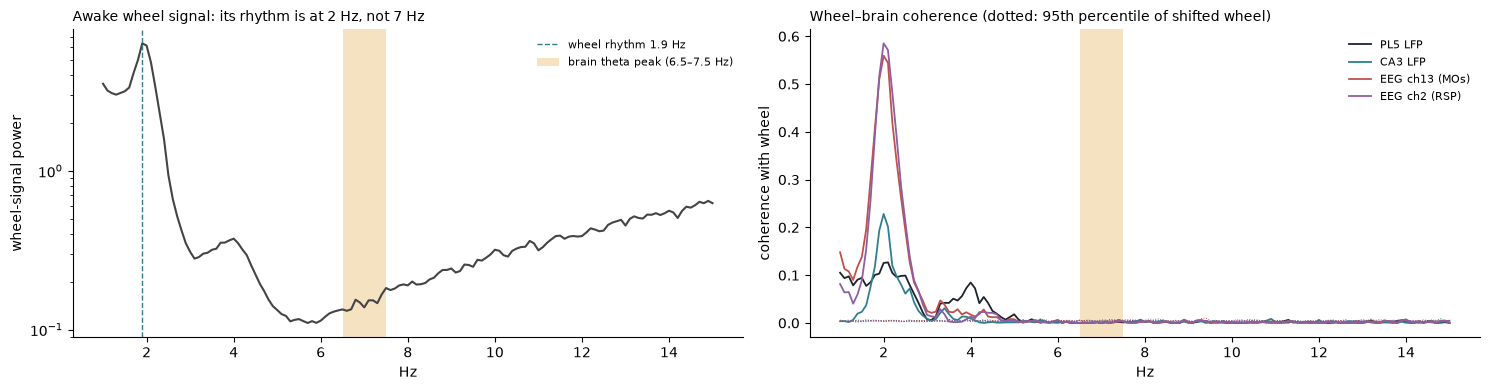

,mean speed (cm/s),wheel rhythm (Hz),PL5 LFP peak (Hz),CA3 LFP peak (Hz),EEG ch13 (MOs) peak (Hz),EEG ch2 (RSP) peak (Hz)
speed third,,,,,,
slow,13.15,1.9,6.6,6.6,6.6,6.6
middle,14.32,1.9,6.6,6.6,6.6,6.6
fast,15.98,2.1,6.9,6.9,6.9,6.9


,coherence at 7 Hz,null95 at 7 Hz,coherence at 1.9 Hz,null95 at 1.9 Hz
PL5 LFP,0.0,0.004,0.103,0.005
CA3 LFP,0.0,0.007,0.193,0.005
EEG ch13 (MOs),0.0,0.004,0.510,0.003
EEG ch2 (RSP),0.0,0.004,0.516,0.005


In [7]:
from scipy.signal import welch, coherence, butter, sosfiltfilt
aw_run = (run_t > tsec[0]) & (run_t < info.iso_on - 30)
w = run[aw_run] - run[aw_run].mean(); tw = run_t[aw_run]
fw, Pw = welch(w, fs=100, nperseg=1000)
band = (fw >= 1) & (fw <= 15)
gait_hz = fw[(fw >= 1) & (fw <= 4)][np.argmax(Pw[(fw >= 1) & (fw <= 4)])]

# neural signals on the wheel's 100-Hz clock (low-passed at 40 Hz first)
io, nwb = sd.open_nwb(NWB)
NEU = {}
for name, src in SOURCES.items():
    t, x, fs = sd.decimate(*sd.read_raw(nwb, src), FS)
    x = sosfiltfilt(butter(4, 40, fs=fs, output="sos"), x)
    NEU[name] = np.interp(tw, t, x)
io.close()

seg = 1000
nseg = w.size // seg
seg_speed = w.reshape(-1)[: nseg * seg].reshape(nseg, seg).mean(1) + run[aw_run].mean()
thirds = np.quantile(seg_speed, [1 / 3, 2 / 3])
grp = np.digitize(seg_speed, thirds)
rows = []
for g, lab in enumerate(("slow", "middle", "fast")):
    segs = np.flatnonzero(grp == g)
    Pg = np.mean([welch(w[s * seg:(s + 1) * seg], fs=100, nperseg=seg)[1] for s in segs], 0)
    row = {"speed third": lab, "mean speed (cm/s)": seg_speed[segs].mean(),
           "wheel rhythm (Hz)": fw[(fw >= 1) & (fw <= 4)][np.argmax(Pg[(fw >= 1) & (fw <= 4)])]}
    for name, x in NEU.items():
        Pn = np.mean([welch(x[s * seg:(s + 1) * seg], fs=100, nperseg=seg)[1] for s in segs], 0)
        win = (fw >= 5) & (fw <= 10)
        row[f"{name} peak (Hz)"] = fw[win][np.argmax(Pn[win])]
    rows.append(row)
by_speed = pd.DataFrame(rows).set_index("speed third")

coh, coh_null = {}, {}
for name, x in NEU.items():
    fc, C = coherence(w, x, fs=100, nperseg=1000)
    coh[name] = C
    coh_null[name] = np.percentile([coherence(np.roll(w, k), x, fs=100, nperseg=1000)[1]
                                    for k in rng.integers(6000, w.size - 6000, 20)], 95, axis=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].semilogy(fw[band], Pw[band], color="#444444")
axes[0].axvline(gait_hz, color="#2F7F8F", ls="--", lw=1, label=f"wheel rhythm {gait_hz:.1f} Hz")
axes[0].axvspan(6.5, 7.5, color="#E0A030", alpha=0.3, lw=0, label="brain theta peak (6.5–7.5 Hz)")
axes[0].set_xlabel("Hz"); axes[0].set_ylabel("wheel-signal power"); axes[0].legend(fontsize=8, frameon=False)
axes[0].set_title("Awake wheel signal: its rhythm is at 2 Hz, not 7 Hz", loc="left", fontsize=10)
k = (fc >= 1) & (fc <= 15)
for (name, C), col in zip(coh.items(), ("#1D232B", "#2F7F8F", "#C2504A", "#8E5EA2")):
    axes[1].plot(fc[k], C[k], color=col, lw=1.3, label=name)
    axes[1].plot(fc[k], coh_null[name][k], color=col, lw=0.7, ls=":")
axes[1].axvspan(6.5, 7.5, color="#E0A030", alpha=0.3, lw=0)
axes[1].set_xlabel("Hz"); axes[1].set_ylabel("coherence with wheel"); axes[1].legend(fontsize=8, frameon=False)
axes[1].set_title("Wheel–brain coherence (dotted: 95th percentile of shifted wheel)", loc="left", fontsize=10)
for a in axes: a.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); save(fig, "4_stride_vs_theta"); plt.show()
i7 = np.argmin(np.abs(fc - 7.0)); i2 = np.argmin(np.abs(fc - gait_hz))
summary = pd.DataFrame({name: {"coherence at 7 Hz": coh[name][i7], "null95 at 7 Hz": coh_null[name][i7],
                               f"coherence at {gait_hz:.1f} Hz": coh[name][i2], f"null95 at {gait_hz:.1f} Hz": coh_null[name][i2]}
                        for name in coh}).T
summary.to_csv(OUT / "stride_coherence.csv"); by_speed.to_csv(OUT / "rhythm_by_speed.csv")
display(by_speed.round(2)); summary.round(3)

## Conclusions

**The awake "7–8 Hz line" is locomotion theta.**
- **Only present while the mouse runs.** It is a narrow peak at about 7 Hz (median 6.5–7 Hz at 0.5-Hz resolution),
  5.8–8.3 dB above its neighbours while awake and about 0 dB under isoflurane, when the mouse never runs. CA3 also shows
  its harmonic near 14 Hz.
- **It drops when running stops.** During induction, stopped seconds have a 7 Hz peak 6.3–7.7 dB lower than running
  seconds in CA3 and both EEG channels, and 2.7 dB lower in PL5.
- **It scales with speed within the awake period** in CA3 and EEG: the fastest fifth is 1.1–2.0 dB above the slowest
  fifth (12.9 vs 15.8 cm/s cut-offs). The relation to speed is weak second by second (Spearman r = 0.09–0.18), and
  absent in PL5 during spontaneous time.
- **Strongest in hippocampus (CA3), then retrosplenial and frontal EEG, weakest in PL5:** consistent with hippocampal
  theta reaching cortex and the scalp by volume conduction or entrainment.

**It is not the stepping rhythm itself.**
- The wheel signal's rhythm, the stride, is at about 2 Hz (1.9–2.1 Hz, rising slightly with speed); it has no peak
  at 7 Hz.
- Brain–wheel coherence at 7 Hz is zero in all four signals: theta is not locked to individual steps.
- Theta's frequency also rises slightly with speed (6.6 → 6.9 Hz from the slowest to the fastest third), so both
  rhythms follow locomotion without being locked to each other: classic locomotion theta.

**The EEG carries the stride.** Wheel–brain coherence at the 2 Hz stride frequency is 0.51–0.58 in both EEG channels
(null 0.005), 0.19 in CA3 and 0.10 in PL5. That points to a step-locked movement artefact (or step-locked activity)
dominating awake EEG at 1–4 Hz, which could be part of why awake EEG motifs are harder to find than LFP ones.

**Implications**
- The mouse runs in essentially every awake second. So "awake" in this session means "awake and running", and the
  awake motifs may partly encode locomotion theta (the 5–9 Hz band). This matters for comparing awake motifs across
  sessions with different behaviour.
- Running and anaesthesia can't be fully separated here. The induction comparison is the cleanest, but stopped
  seconds come later in induction, when the drug is deeper.
- The shuffle p-values ignore autocorrelation and are optimistic; the effect sizes are the main evidence.